In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
sns.set_style("darkgrid")

In [3]:
df = pd.read_csv("data/raw/waze_dataset.csv")

In [4]:
df.head()

,ID,label,sessions,drives,total_sessions,n_days_after_onboarding,total_navigations_fav1,total_navigations_fav2,driven_km_drives,duration_minutes_drives,activity_days,driving_days,device
0,0,retained,283,226,296.748273,2276,208,0,2628.845068,1985.775061,28,19,Android
1,1,retained,133,107,326.896596,1225,19,64,13715.920550,3160.472914,13,11,iPhone
2,2,retained,114,95,135.522926,2651,0,0,3059.148818,1610.735904,14,8,Android
3,3,retained,49,40,67.589221,15,322,7,913.591123,587.196542,7,3,iPhone
4,4,retained,84,68,168.247020,1562,166,5,3950.202008,1219.555924,27,18,Android


In [5]:
df.label.unique()

array(['retained', 'churned', nan], dtype=object)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       14999 non-null  int64  
 1   label                    14299 non-null  object 
 2   sessions                 14999 non-null  int64  
 3   drives                   14999 non-null  int64  
 4   total_sessions           14999 non-null  float64
 5   n_days_after_onboarding  14999 non-null  int64  
 6   total_navigations_fav1   14999 non-null  int64  
 7   total_navigations_fav2   14999 non-null  int64  
 8   driven_km_drives         14999 non-null  float64
 9   duration_minutes_drives  14999 non-null  float64
 10  activity_days            14999 non-null  int64  
 11  driving_days             14999 non-null  int64  
 12  device                   14999 non-null  object 
dtypes: float64(3), int64(8), object(2)
memory usage: 1.5+ MB


In [7]:
df.isnull().sum()

ID                           0
label                      700
sessions                     0
drives                       0
total_sessions               0
n_days_after_onboarding      0
total_navigations_fav1       0
total_navigations_fav2       0
driven_km_drives             0
duration_minutes_drives      0
activity_days                0
driving_days                 0
device                       0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.describe()

,ID,sessions,drives,total_sessions,n_days_after_onboarding,total_navigations_fav1,total_navigations_fav2,driven_km_drives,duration_minutes_drives,activity_days,driving_days
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000
mean,7499.000000,80.633776,67.281152,189.964447,1749.837789,121.605974,29.672512,4039.340921,1860.976012,15.537102,12.179879
std,4329.982679,80.699065,65.913872,136.405128,1008.513876,148.121544,45.394651,2502.149334,1446.702288,9.004655,7.824036
min,0.000000,0.000000,0.000000,0.220211,4.000000,0.000000,0.000000,60.441250,18.282082,0.000000,0.000000
25%,3749.500000,23.000000,20.000000,90.661156,878.000000,9.000000,0.000000,2212.600607,835.996260,8.000000,5.000000
50%,7499.000000,56.000000,48.000000,159.568115,1741.000000,71.000000,9.000000,3493.858085,1478.249859,16.000000,12.000000
75%,11248.500000,112.000000,93.000000,254.192341,2623.500000,178.000000,43.000000,5289.861262,2464.362632,23.000000,19.000000
max,14998.000000,743.000000,596.000000,1216.154633,3500.000000,1236.000000,415.000000,21183.401890,15851.727160,31.000000,30.000000


In [10]:
df[df.label.isnull()].describe()

,ID,sessions,drives,total_sessions,n_days_after_onboarding,total_navigations_fav1,total_navigations_fav2,driven_km_drives,duration_minutes_drives,activity_days,driving_days
count,700.000000,700.000000,700.000000,700.000000,700.000000,700.000000,700.000000,700.000000,700.000000,700.000000,700.000000
mean,7405.584286,80.837143,67.798571,198.483348,1709.295714,118.717143,30.371429,3935.967029,1795.123358,15.382857,12.125714
std,4306.900234,79.987440,65.271926,140.561715,1005.306562,156.308140,46.306984,2443.107121,1419.242246,8.772714,7.626373
min,77.000000,0.000000,0.000000,5.582648,16.000000,0.000000,0.000000,290.119811,66.588493,0.000000,0.000000
25%,3744.500000,23.000000,20.000000,94.056340,869.000000,4.000000,0.000000,2119.344818,779.009271,8.000000,6.000000
50%,7443.000000,56.000000,47.500000,177.255925,1650.500000,62.500000,10.000000,3421.156721,1414.966279,15.000000,12.000000
75%,11007.000000,112.250000,94.000000,266.058022,2508.750000,169.250000,43.000000,5166.097373,2443.955404,23.000000,18.000000
max,14993.000000,556.000000,445.000000,1076.879741,3498.000000,1096.000000,352.000000,15135.391280,9746.253023,31.000000,30.000000


In [11]:
df.label.value_counts(normalize=True)

label
retained    0.822645
churned     0.177355
Name: proportion, dtype: float64

In [12]:
df.drop(["device", "ID"], axis=1).groupby("label").agg(["mean", "median"])

sessions            drives        total_sessions              \
               mean median       mean median           mean      median   
label                                                                     
churned   87.238959   59.0  72.730678   50.0     196.893424  164.339042   
retained  79.197654   56.0  66.075491   47.0     187.963672  157.586756   

         n_days_after_onboarding         total_navigations_fav1         \
                            mean  median                   mean median   
label                                                                    
churned              1471.027603  1321.0             139.414826   84.5   
retained             1812.359432  1843.0             117.938451   68.0   

         total_navigations_fav2        driven_km_drives               \
                           mean median             mean       median   
label                                                                  
churned               31.596609   11.0      4147.171864  3652.655666   
retained              29.216101    9.0      4022.245150  3464.684614   

         duration_minutes_drives              activity_days         \
                            mean       median          mean median   
label                                                                
churned              1975.459630  1607.183785      9.644716    8.0   
retained             1840.213146  1458.046141     16.816628   17.0   

         driving_days         
                 mean median  
label                         
churned      7.218060    6.0  
retained    13.252827   14.0

Users who churned averaged ~3 more drives in the last month than retained users, but retained users used the app on over twice as many days as churned users in the same time period.

The median churned user drove ~200 more kilometers and 2.5 more hours during the last month than the median retained user.

It seems that churned users had more drives in fewer days, and their trips were farther and longer in duration.

In [13]:
# Add a column to df called `km_per_driving_day`
df["km_per_driving_day"] = df["driven_km_drives"] / df["driving_days"]

# Group by `label`, calculate the median, and isolate for km per driving day
median_km_per_driving_day = df.groupby("label").median(numeric_only=True)[
    ["km_per_driving_day"]
]
median_km_per_driving_day

,km_per_driving_day
label,
churned,697.541999
retained,289.549333


Churned people drive way more per day

In [14]:
# Add a column to df called `drives_per_driving_day`
df["drives_per_driving_day"] = df["drives"] / df["driving_days"]

# Group by `label`, calculate the median, and isolate for drives per driving day
median_drives_per_driving_day = df.groupby("label").median(numeric_only=True)[
    ["drives_per_driving_day"]
]
median_drives_per_driving_day

,drives_per_driving_day
label,
churned,10.0000
retained,4.0625


The median user who churned drove 698 kilometers each day they drove last month, which is ~240% the per-drive-day distance of retained users. The median churned user had a similarly disproporionate number of drives per drive day compared to retained users.

It is clear from these figures that, regardless of whether a user churned or not, the users represented in this data are serious drivers! It would probably be safe to assume that this data does not represent typical drivers at large. Perhaps the data&mdash;and in particular the sample of churned users&mdash;contains a high proportion of long-haul truckers.


In [15]:
df.groupby(["label", "device"]).size()

label     device 
churned   Android     891
          iPhone     1645
retained  Android    4183
          iPhone     7580
dtype: int64

In [16]:
df.groupby("label")["device"].value_counts(normalize=True)

label     device 
churned   iPhone     0.648659
          Android    0.351341
retained  iPhone     0.644393
          Android    0.355607
Name: proportion, dtype: float64

In [17]:
df.device.value_counts(normalize=True)

device
iPhone     0.644843
Android    0.355157
Name: proportion, dtype: float64

The ratio of iPhone users and Android users is consistent between the churned group and the retained group, and those ratios are both consistent with the ratio found in the overall dataset.

# Univariate Analysis

In [18]:
df.columns

Index(['ID', 'label', 'sessions', 'drives', 'total_sessions',
       'n_days_after_onboarding', 'total_navigations_fav1',
       'total_navigations_fav2', 'driven_km_drives', 'duration_minutes_drives',
       'activity_days', 'driving_days', 'device', 'km_per_driving_day',
       'drives_per_driving_day'],
      dtype='object')

In [19]:
def inspect(feature: str):
    print(df[feature].describe())
    fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(6, 4), sharex=True)

    sns.boxplot(data=df, x=feature, ax=axes[0])
    axes[0].set_title(f"distribution of {feature}")
    sns.histplot(data=df, x=feature, ax=axes[1], hue="label")
    median = df[feature].median()
    plt.axvline(median, color="red", linestyle="--")
    plt.tight_layout()
    plt.show()

### Sessions

count    14999.000000
mean        80.633776
std         80.699065
min          0.000000
25%         23.000000
50%         56.000000
75%        112.000000
max        743.000000
Name: sessions, dtype: float64


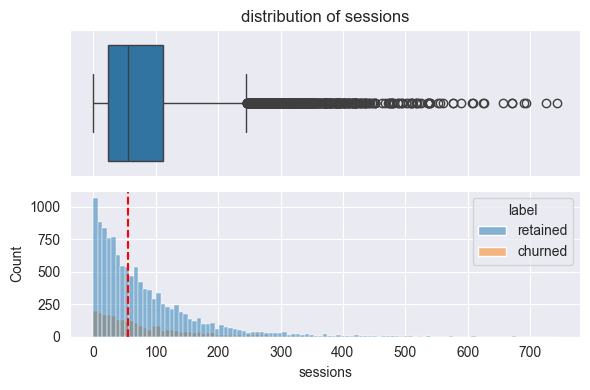

In [20]:
inspect("sessions")

Very heavily right skewed

### Drives

count    14999.000000
mean        67.281152
std         65.913872
min          0.000000
25%         20.000000
50%         48.000000
75%         93.000000
max        596.000000
Name: drives, dtype: float64


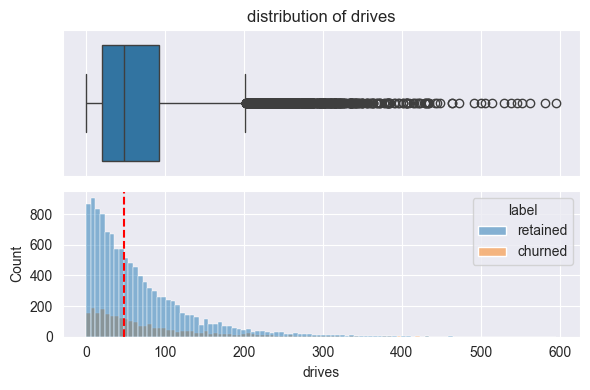

In [21]:
inspect("drives")

### Total Sessions

count    14999.000000
mean       189.964447
std        136.405128
min          0.220211
25%         90.661156
50%        159.568115
75%        254.192341
max       1216.154633
Name: total_sessions, dtype: float64


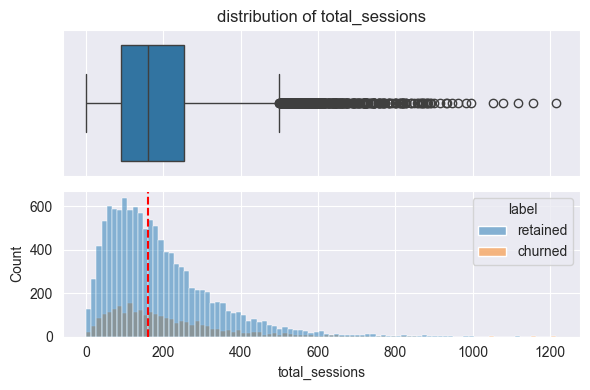

In [22]:
inspect("total_sessions")

### n_days_after_onboarding

count    14999.000000
mean      1749.837789
std       1008.513876
min          4.000000
25%        878.000000
50%       1741.000000
75%       2623.500000
max       3500.000000
Name: n_days_after_onboarding, dtype: float64


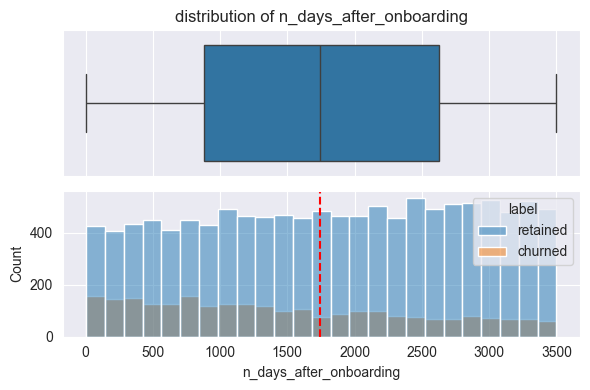

In [23]:
inspect("n_days_after_onboarding")

### total_navigations_fav1

count    14999.000000
mean       121.605974
std        148.121544
min          0.000000
25%          9.000000
50%         71.000000
75%        178.000000
max       1236.000000
Name: total_navigations_fav1, dtype: float64


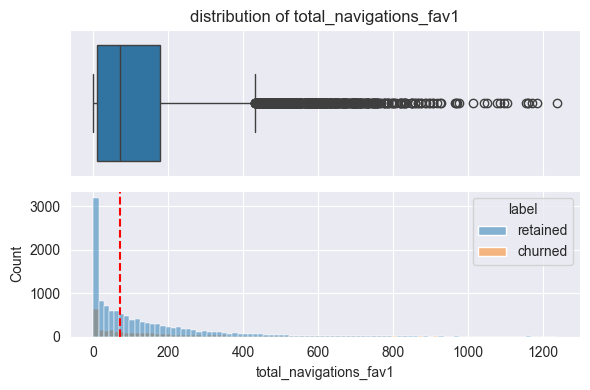

In [24]:
inspect("total_navigations_fav1")

### total_navigations_fav2

count    14999.000000
mean        29.672512
std         45.394651
min          0.000000
25%          0.000000
50%          9.000000
75%         43.000000
max        415.000000
Name: total_navigations_fav2, dtype: float64


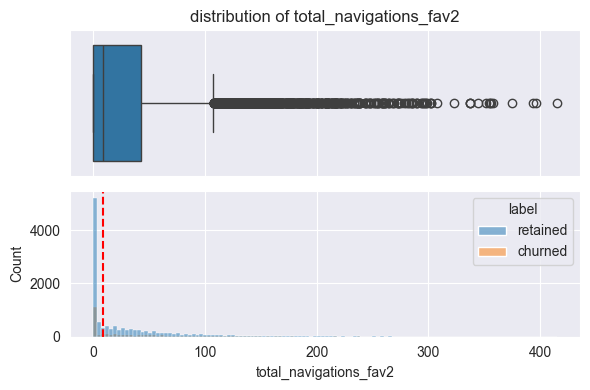

In [25]:
inspect("total_navigations_fav2")

### driven_km_drives

count    14999.000000
mean      4039.340921
std       2502.149334
min         60.441250
25%       2212.600607
50%       3493.858085
75%       5289.861262
max      21183.401890
Name: driven_km_drives, dtype: float64


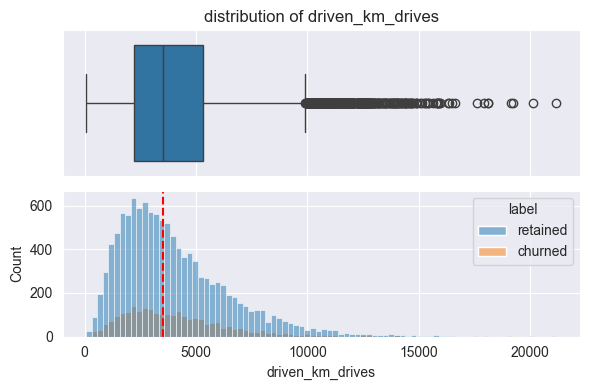

In [26]:
inspect("driven_km_drives")

### duration_minutes_drives

count    14999.000000
mean      1860.976012
std       1446.702288
min         18.282082
25%        835.996260
50%       1478.249859
75%       2464.362632
max      15851.727160
Name: duration_minutes_drives, dtype: float64


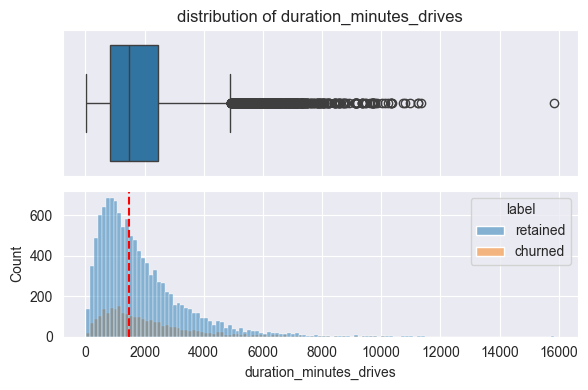

In [27]:
inspect("duration_minutes_drives")

### activity_days

count    14999.000000
mean        15.537102
std          9.004655
min          0.000000
25%          8.000000
50%         16.000000
75%         23.000000
max         31.000000
Name: activity_days, dtype: float64


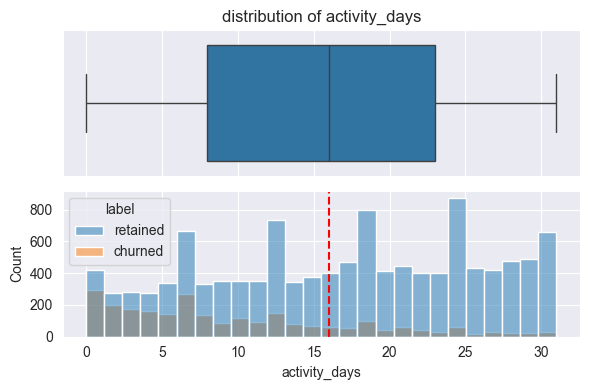

In [28]:
inspect("activity_days")

### driving_days

count    14999.000000
mean        12.179879
std          7.824036
min          0.000000
25%          5.000000
50%         12.000000
75%         19.000000
max         30.000000
Name: driving_days, dtype: float64


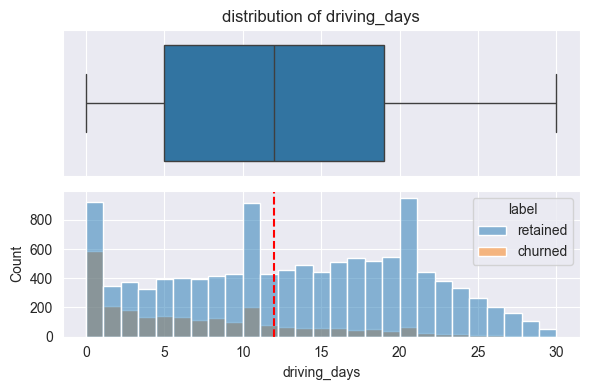

In [29]:
inspect("driving_days")

### Devices

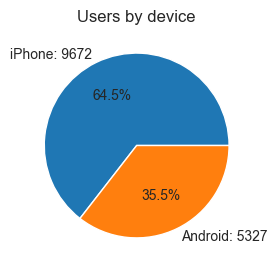

In [30]:
fig = plt.figure(figsize=(3, 3))
data = df["device"].value_counts()
plt.pie(
    data,
    labels=[f"{data.index[0]}: {data.values[0]}", f"{data.index[1]}: {data.values[1]}"],
    autopct="%1.1f%%",
)
plt.title("Users by device");

### Label

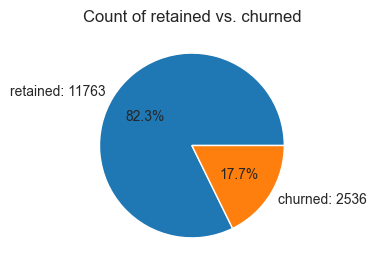

In [31]:
# Pie chart
fig = plt.figure(figsize=(3, 3))
data = df["label"].value_counts()
plt.pie(
    data,
    labels=[f"{data.index[0]}: {data.values[0]}", f"{data.index[1]}: {data.values[1]}"],
    autopct="%1.1f%%",
)
plt.title("Count of retained vs. churned");

In [32]:
df.columns

Index(['ID', 'label', 'sessions', 'drives', 'total_sessions',
       'n_days_after_onboarding', 'total_navigations_fav1',
       'total_navigations_fav2', 'driven_km_drives', 'duration_minutes_drives',
       'activity_days', 'driving_days', 'device', 'km_per_driving_day',
       'drives_per_driving_day'],
      dtype='object')

### Activity vs Driving

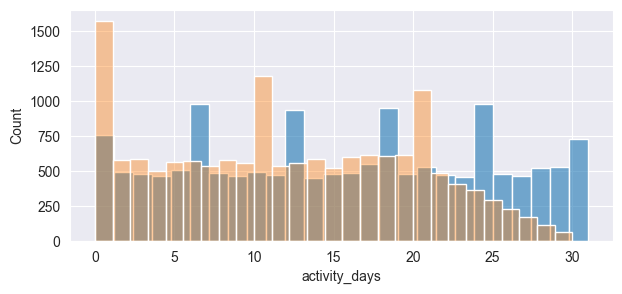

In [33]:
plt.figure(figsize=(7, 3))
sns.histplot(
    df,
    x="activity_days",
    alpha=0.6,
)
sns.histplot(
    df,
    x="driving_days",
    alpha=0.4,
);

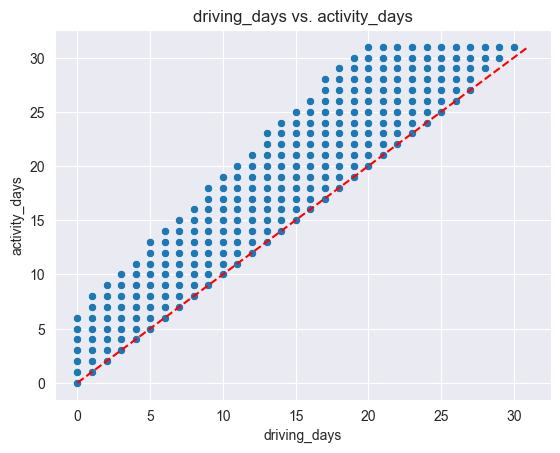

In [34]:
sns.scatterplot(data=df, x="driving_days", y="activity_days")
plt.title("driving_days vs. activity_days")
plt.plot([0, 31], [0, 31], color="red", linestyle="--");

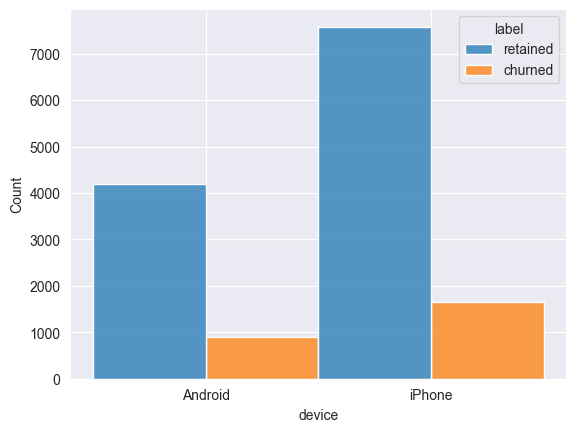

In [35]:
sns.histplot(data=df, x="device", hue="label", multiple="dodge");

In [ ]:
df["km_per_driving_day"] = df["driven_km_drives"] / df["driving_days"]

# 2. Call `describe()` on the new column
df["km_per_driving_day"].describe()

c:\Users\Sarvamm\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


count    1.499900e+04
mean              inf
std               NaN
min      3.022063e+00
25%      1.672804e+02
50%      3.231459e+02
75%      7.579257e+02
max               inf
Name: km_per_driving_day, dtype: float64

In [ ]:
# 1. Convert infinite values to zero
df.loc[df["km_per_driving_day"] == np.inf, "km_per_driving_day"] = 0

# 2. Confirm that it worked
df["km_per_driving_day"].describe()

count    14999.000000
mean       578.963113
std       1030.094384
min          0.000000
25%        136.238895
50%        272.889272
75%        558.686918
max      15420.234110
Name: km_per_driving_day, dtype: float64

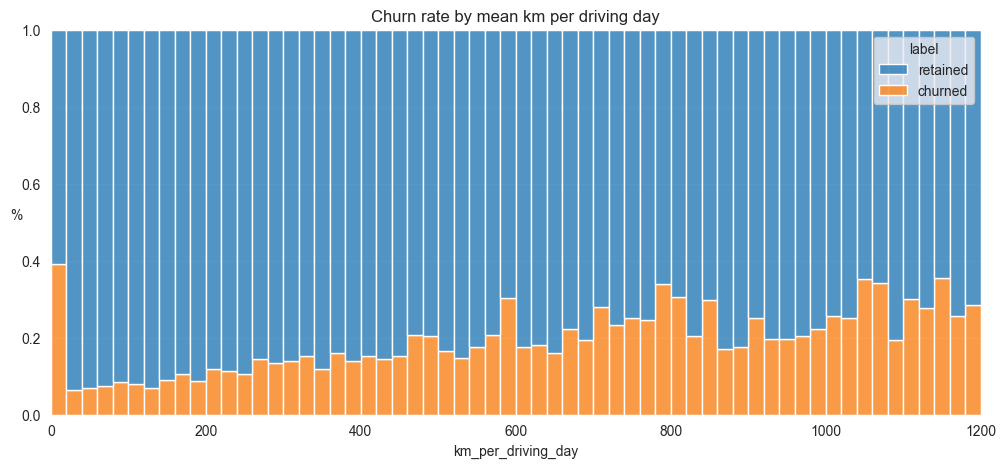

In [ ]:
# Histogram
plt.figure(figsize=(12, 5))
sns.histplot(
    data=df,
    x="km_per_driving_day",
    bins=range(0, 1201, 20),
    hue="label",
    multiple="fill",
)
plt.ylabel("%", rotation=0)
plt.title("Churn rate by mean km per driving day");

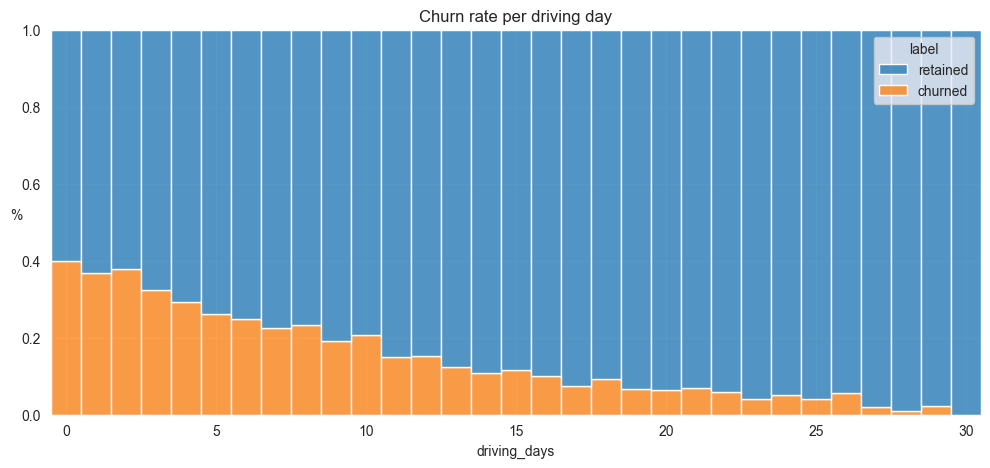

In [ ]:
# Histogram
plt.figure(figsize=(12, 5))
sns.histplot(
    data=df,
    x="driving_days",
    bins=range(1, 32),
    hue="label",
    multiple="fill",
    discrete=True,
)
plt.ylabel("%", rotation=0)
plt.title("Churn rate per driving day");

In [ ]:
df["percent_sessions_in_last_month"] = df["sessions"] / df["total_sessions"]

In [ ]:
df["percent_sessions_in_last_month"].median()

np.float64(0.42309702992763176)

count    14999.000000
mean         0.449255
std          0.286919
min          0.000000
25%          0.196221
50%          0.423097
75%          0.687216
max          1.530637
Name: percent_sessions_in_last_month, dtype: float64


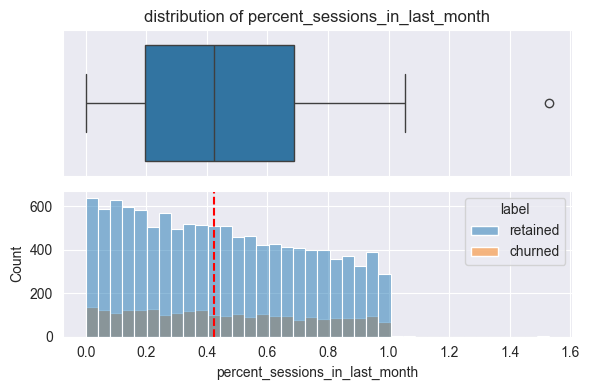

In [ ]:
inspect("percent_sessions_in_last_month")

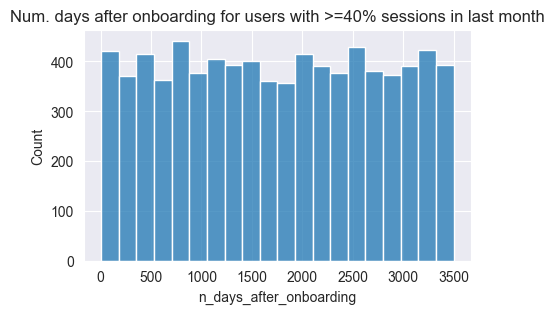

In [ ]:
data = df.loc[df["percent_sessions_in_last_month"] >= 0.4]
plt.figure(figsize=(5, 3))
sns.histplot(x=data["n_days_after_onboarding"])
plt.title("Num. days after onboarding for users with >=40% sessions in last month");

In [ ]:
def outlier_imputer(column_name, percentile):
    # Calculate threshold
    threshold = df[column_name].quantile(percentile)
    # Impute threshold for values > than threshold
    df.loc[df[column_name] > threshold, column_name] = threshold

    print(
        "{:>25} | percentile: {} | threshold: {}".format(
            column_name, percentile, threshold
        )
    )

In [ ]:
for column in [
    "sessions",
    "drives",
    "total_sessions",
    "driven_km_drives",
    "duration_minutes_drives",
]:
    outlier_imputer(column, 0.95)

                 sessions | percentile: 0.95 | threshold: 243.0
                   drives | percentile: 0.95 | threshold: 201.0
           total_sessions | percentile: 0.95 | threshold: 454.3632037399997
         driven_km_drives | percentile: 0.95 | threshold: 8889.7942356
  duration_minutes_drives | percentile: 0.95 | threshold: 4668.899348999998


# Hypothesis testing

"Do drivers who open the application using an iPhone have the same number of drives on average as drivers who use Android devices?"

In [ ]:
# 1. Create `map_dictionary`
map_dictionary = {"Android": 2, "iPhone": 1}

# 2. Create new `device_type` column
df["device_type"] = df["device"]

# 3. Map the new column to the dictionary
df["device_type"] = df["device_type"].map(map_dictionary)

df["device_type"].head()

0    2
1    1
2    2
3    1
4    2
Name: device_type, dtype: int64

In [ ]:
df.groupby("device_type")["drives"].mean()

device_type
1    64.446340
2    63.353482
Name: drives, dtype: float64


**Hypotheses:**

$H_0$: There is no difference in average number of drives between drivers who use iPhone devices and drivers who use Androids.

$H_A$: There is a difference in average number of drives between drivers who use iPhone devices and drivers who use Androids.

In [ ]:
# 1. Isolate the `drives` column for iPhone users.
iPhone = df[df["device_type"] == 1]["drives"]

# 2. Isolate the `drives` column for Android users.
Android = df[df["device_type"] == 2]["drives"]

# 3. Perform the t-test
stats.ttest_ind(a=iPhone, b=Android, equal_var=False)

TtestResult(statistic=np.float64(1.1643714136026293), pvalue=np.float64(0.24429844267242218), df=np.float64(11148.669519764011))

> *Since the p-value is larger than the chosen significance level (5%), you fail to reject the null hypothesis. You conclude that there is **not** a statistically significant difference in the average number of drives between drivers who use iPhones and drivers who use Androids.*

In [50]:
df.to_csv("data/processed/waze_dataset.csv")